In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams["figure.dpi"] = 150
plt.rcParams["axes.facecolor"] = "#f4f7fc"
plt.rcParams["axes.edgecolor"] = "#dce4f0"

df = pd.read_csv("student_data.csv")
model = joblib.load("student_model.pkl")

features = [
    "Study_Hours",
    "Attendance",
    "Previous_Score",
    "Sleep_Hours",
    "Assignment_Average",
    "Practice_Tests",
]
target = "Final_Score"

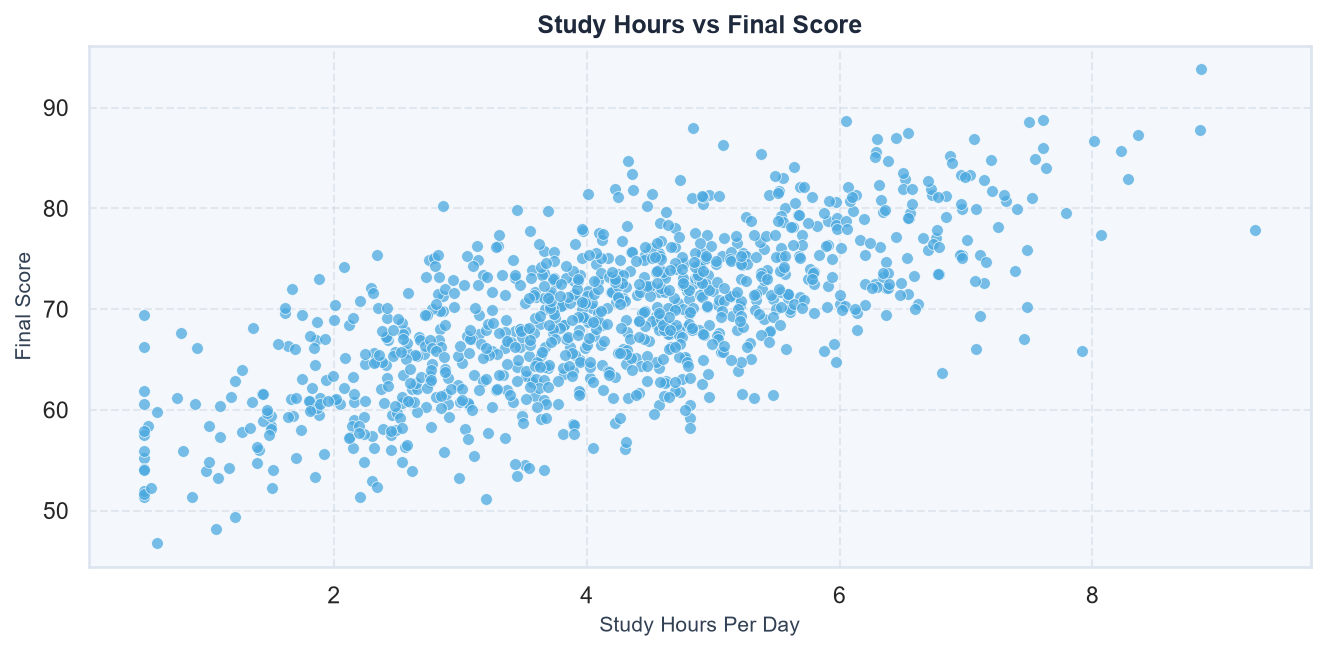

In [7]:
plt.figure(figsize=(9, 4.5))
plt.scatter(
    df["Study_Hours"],
    df["Final_Score"],
    color="#4aa8e0",
    s=32,
    alpha=0.75,
    edgecolors="#ffffff",
    linewidth=0.4,
)
plt.title(
    "Study Hours vs Final Score", fontsize=12, fontweight="bold", color="#1e293b"
)
plt.xlabel("Study Hours Per Day", fontsize=10, color="#334155")
plt.ylabel("Final Score", fontsize=10, color="#334155")
plt.grid(True, linestyle="--", alpha=0.45, color="#cbd5e1")
plt.tight_layout()
plt.show()

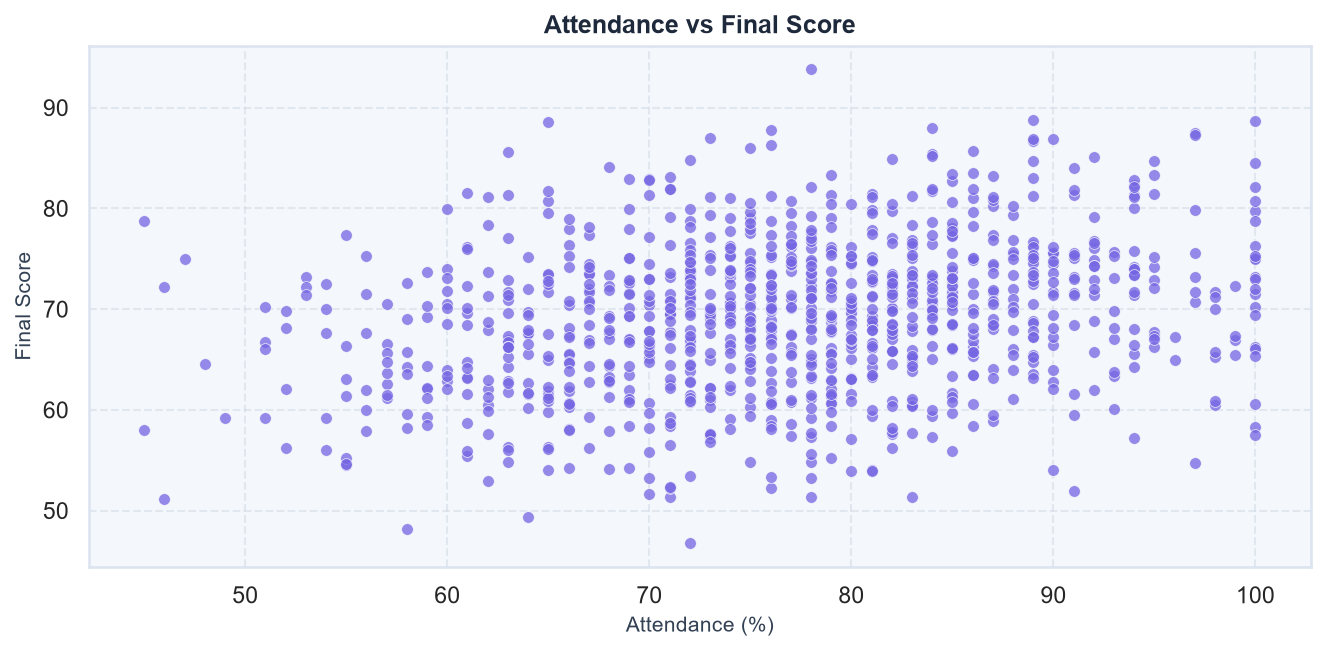

In [8]:
plt.figure(figsize=(9, 4.5))
plt.scatter(
    df["Attendance"],
    df["Final_Score"],
    color="#7465e2",
    s=32,
    alpha=0.75,
    edgecolors="#ffffff",
    linewidth=0.4,
)
plt.title(
    "Attendance vs Final Score", fontsize=12, fontweight="bold", color="#1e293b"
)
plt.xlabel("Attendance (%)", fontsize=10, color="#334155")
plt.ylabel("Final Score", fontsize=10, color="#334155")
plt.grid(True, linestyle="--", alpha=0.45, color="#cbd5e1")
plt.tight_layout()
plt.show()

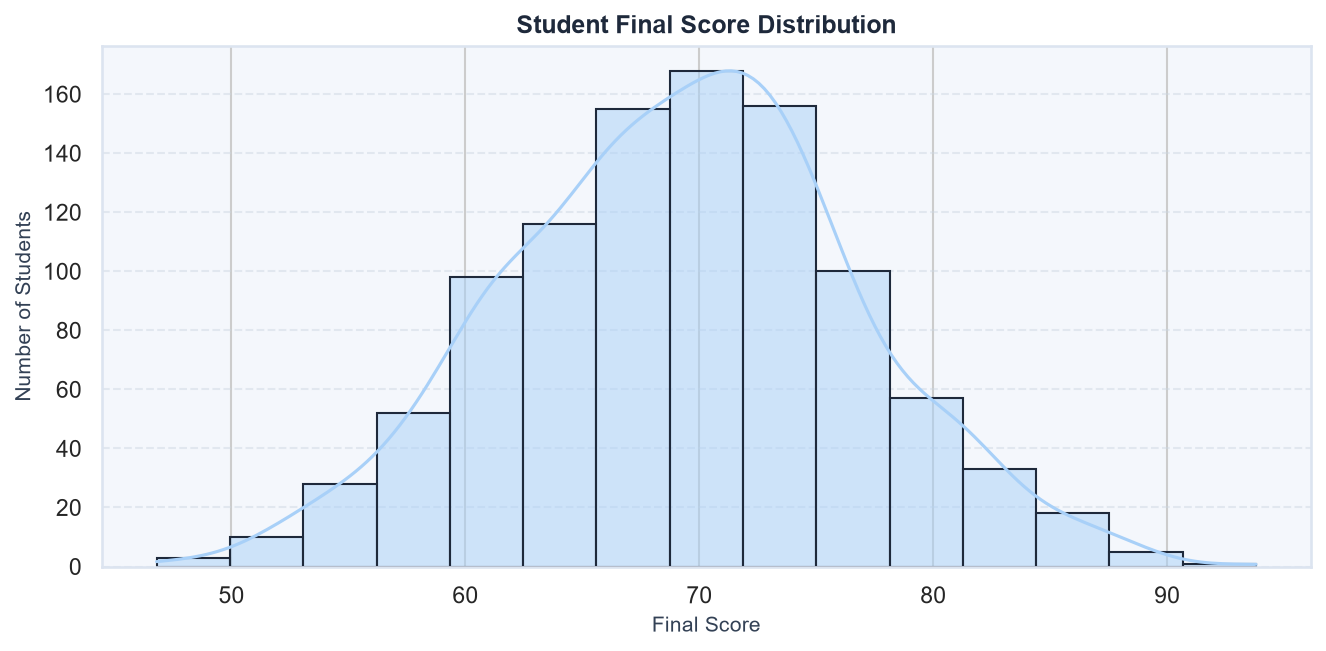

In [9]:
plt.figure(figsize=(9, 4.5))
sns.histplot(
    df["Final_Score"], bins=15, kde=True, color="#a8d0f8", edgecolor="#1e293b"
)
plt.title(
    "Student Final Score Distribution",
    fontsize=12,
    fontweight="bold",
    color="#1e293b",
)
plt.xlabel("Final Score", fontsize=10, color="#334155")
plt.ylabel("Number of Students", fontsize=10, color="#334155")
plt.grid(axis="y", linestyle="--", alpha=0.45, color="#cbd5e1")
plt.tight_layout()
plt.show()

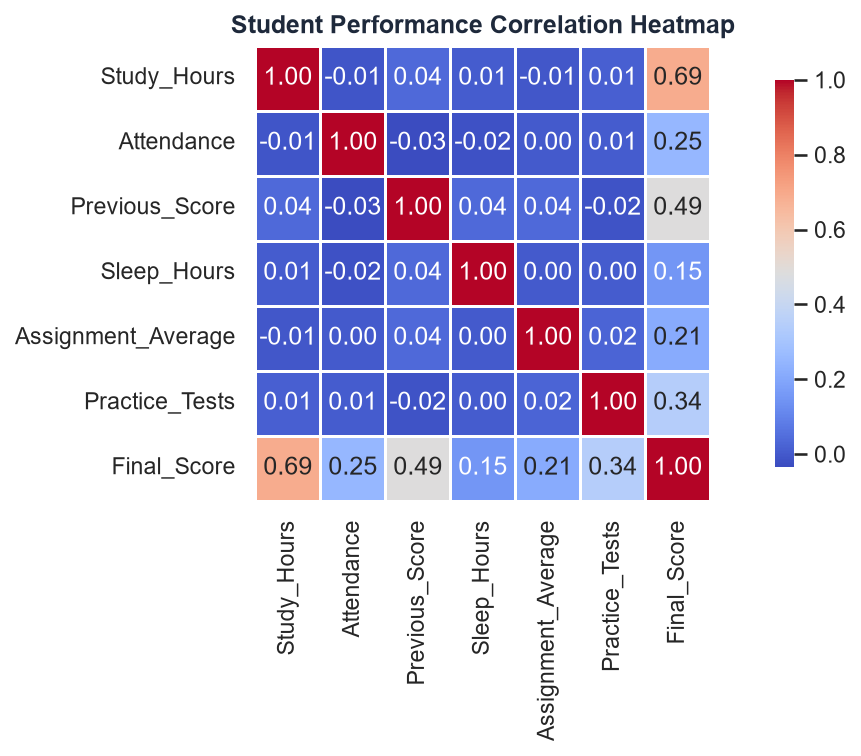

In [10]:
plt.figure(figsize=(9, 5.2))
sns.heatmap(
    df[features + [target]].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.6,
    square=True,
    cbar_kws={"shrink": 0.85},
)
plt.title(
    "Student Performance Correlation Heatmap",
    fontsize=12,
    fontweight="bold",
    color="#1e293b",
)
plt.tight_layout()
plt.show()

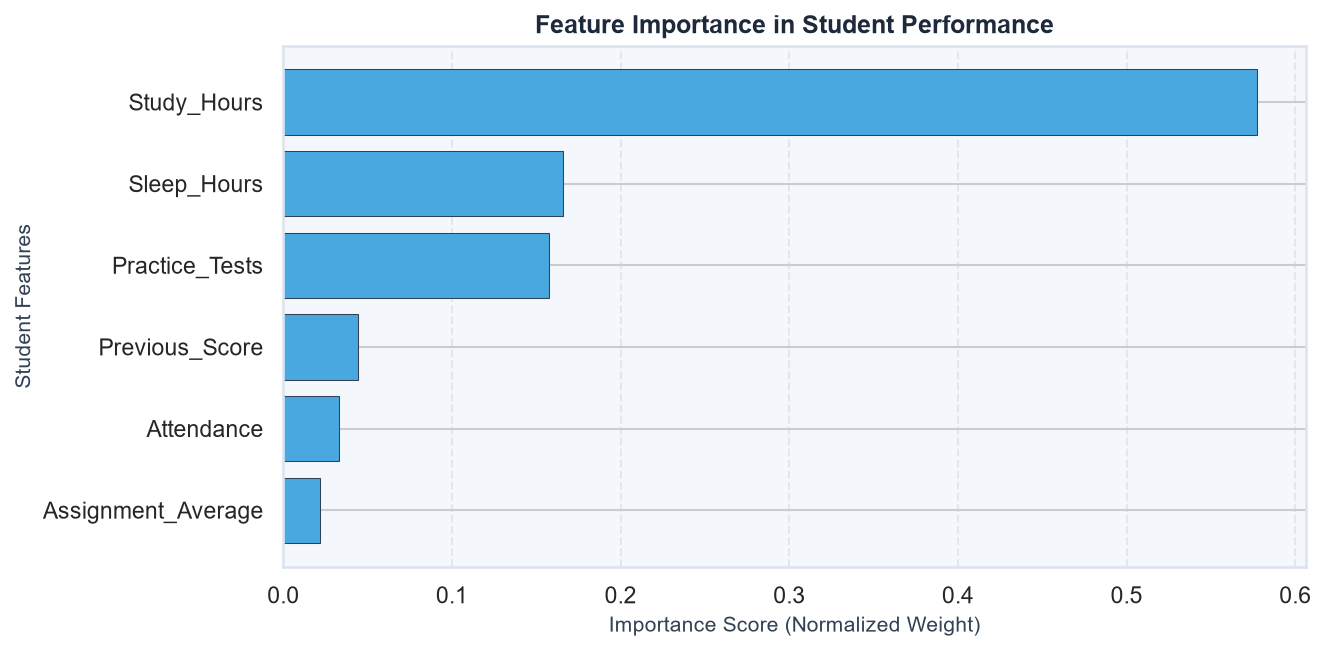

In [11]:
weights = pd.Series(np.abs(model.coef_), index=features)
weights_norm = (weights / weights.sum()).sort_values(ascending=True)

plt.figure(figsize=(9, 4.5))
plt.barh(
    weights_norm.index,
    weights_norm.values,
    color="#4aa8e0",
    edgecolor="#334155",
    linewidth=0.5,
)
plt.title(
    "Feature Importance in Student Performance",
    fontsize=12,
    fontweight="bold",
    color="#1e293b",
)
plt.xlabel("Importance Score (Normalized Weight)", fontsize=10, color="#334155")
plt.ylabel("Student Features", fontsize=10, color="#334155")
plt.grid(axis="x", linestyle="--", alpha=0.45, color="#cbd5e1")
plt.tight_layout()
plt.show()